In [1]:
# Question 3.1
# Import the required libraries
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nltk.stem import SnowballStemmer

from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD, NMF


In [2]:
# Question 3.1
# Read all five text files
files = [Path(f"../datasets/research_{i}.txt") for i in range(1, 6)]

records = []

for i, file in enumerate(files, start=1):

    content = file.read_text(encoding="utf-8-sig")

    records.append({
        "Article": f"Article {i}",
        "Filename": file.name,
        "Content": content,
        "Word_Count": len(content.split())
    })

# Create the DataFrame
df = pd.DataFrame(records)

# Display the dataset
print("Number of articles:", len(df))
display(df)

# Preview content of the first article
print("\nFirst article preview:\n", df.loc[0, "Content"][:500])


Number of articles: 5


,Article,Filename,Content,Word_Count
0,Article 1,research_1.txt,The purposes of this article are to position m...,5602
1,Article 2,research_2.txt,"Now I see it, now I don’t:\nresearcher’s posit...",2416
2,Article 3,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...,3828
3,Article 4,research_4.txt,Abstract\nCronbach’s alpha is a statistic comm...,5922
4,Article 5,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulat...,4027



First article preview:
 The purposes of this article are to position mixed methods research
(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism
as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting
mixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative


In [3]:
# Question 3.2
# Define stop words
stop_words = set(ENGLISH_STOP_WORDS) | {
    "et", "al", "http", "https", "www",
    "doi", "article", "articles", "author", "authors"
}

# Create the stemmer
stemmer = SnowballStemmer("english")

# Function to clean research text
def clean_text(text):

    # Normalize Unicode characters
    text = unicodedata.normalize("NFKC", text)

    # Repair words broken across lines
    text = re.sub(r"(?<=\w)-\s*\n\s*(?=\w)", "", text)

    # Remove URLs and email addresses
    text = re.sub(
        r"https?://\S+|www\.\S+|\S+@\S+",
        " ", text
    )

    # Convert to lowercase and remove special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text.lower())

    # Remove short words and stop words
    words = re.findall(r"[a-z]{3,}", text)

    return " ".join(
        word for word in words if word not in stop_words
    )

# Apply preprocessing
df["Clean_Text"] = df["Content"].apply(clean_text)

# Apply stemming
df["Stemmed_Text"] = df["Clean_Text"].apply(
    lambda text: " ".join(
        stemmer.stem(word) for word in text.split()
    )
)

# Calculate cleaned word counts
df["Clean_Word_Count"] = (
    df["Clean_Text"].str.split().str.len()
)

# Display results
display(df[[
    "Article", "Word_Count", "Clean_Word_Count"
]])

print("\nExample cleaned text:\n",
      df.loc[0, "Clean_Text"][:350])

print("\nExample stemmed text:\n",
      df.loc[0, "Stemmed_Text"][:350])


,Article,Word_Count,Clean_Word_Count
0,Article 1,5602,2946
1,Article 2,2416,1196
2,Article 3,3828,1992
3,Article 4,5922,2974
4,Article 5,4027,2109



Example cleaned text:
 purposes position mixed methods research mixed research synonym natural complement traditional qualitative quantitative research present pragmatism offering attractive philosophical partner mixed methods research provide framework designing conducting mixed methods research doing briefly review paradigm wars incompatibility thesis commonalities qua

Example stemmed text:
 purpos posit mix method research mix research synonym natur complement tradit qualit quantit research present pragmat offer attract philosoph partner mix method research provid framework design conduct mix method research do briefli review paradigm war incompat thesi common quantit qualit research explain tenet pragmat explain fundament principl mi


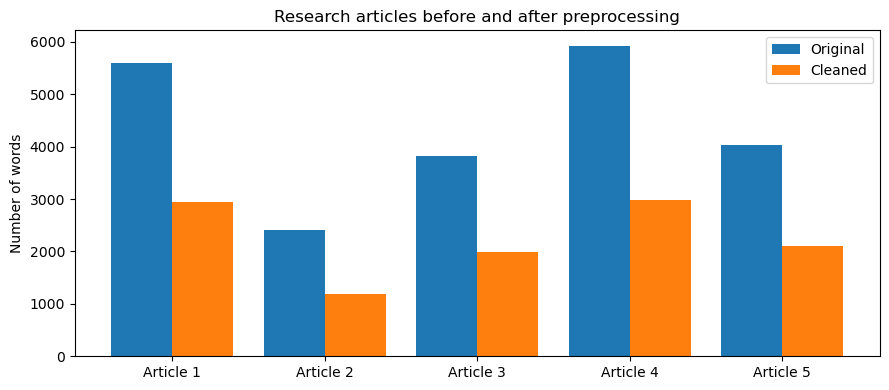

In [4]:
# Question 3.2
# Compare word counts before and after preprocessing
positions = np.arange(len(df))

plt.figure(figsize=(9, 4))

plt.bar(
    positions - 0.2,
    df["Word_Count"],
    width=0.4,
    label="Original"
)

plt.bar(
    positions + 0.2,
    df["Clean_Word_Count"],
    width=0.4,
    label="Cleaned"
)

plt.xticks(positions, df["Article"])
plt.ylabel("Number of words")
plt.title("Research articles before and after preprocessing")
plt.legend()
plt.tight_layout()
plt.show()


In [5]:
# Question 3.3
# Function to split research articles into sentences
def get_sentences(text):

    # Repair broken words and spaces
    text = re.sub(r"(?<=\w)-\s*\n\s*(?=\w)", "", text)
    text = re.sub(r"\s+", " ", text)

    # Split the text into sentences
    sentences = re.split(
        r'(?<=[.!?])\s+(?=[A-Z“"0-9])',
        text
    )

    # Remove repeated and unsuitable sentences
    unique = []
    seen = set()

    for sentence in sentences:

        if not 12 <= len(sentence.split()) <= 75:
            continue

        key = re.sub(
            r"[^a-z]+", " ", sentence.lower()
        ).strip()

        if key not in seen:
            seen.add(key)
            unique.append(sentence.strip())

    return unique

# Extract sentences from Article 1
first_sentences = get_sentences(df.loc[0, "Content"])

print("Usable sentences in Article 1:",
      len(first_sentences))


Usable sentences in Article 1: 71


In [6]:
# Question 3.3
# Convert sentences into TF-IDF features
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=5000
)

sentence_vectors = tfidf.fit_transform(first_sentences)

# Calculate average TF-IDF representation
article_vector = np.asarray(
    sentence_vectors.mean(axis=0)
)

# Calculate sentence importance scores
sentence_scores = cosine_similarity(
    sentence_vectors,
    article_vector
).ravel()

# Select five important sentences
summary_ids = sorted(
    np.argsort(sentence_scores)[-5:]
)

# Display the summary
print("SUMMARY OF ARTICLE 1:\n")

for i in summary_ids:
    print(first_sentences[i], "\n")


SUMMARY OF ARTICLE 1:

The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research. 

In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative research, we explain the tenets of pragmatism, we explain the fundamental principle of mixed research and how to apply it, we provide specific sets of designs for the two major types of mixed methods research (mixed-model designs and mixed-method designs), and, finally, we explain mixed methods research as following (recursively) an eight-step process. 

Our purpose in writing this article is to present mixed methods research as the third research paradigm in educationa

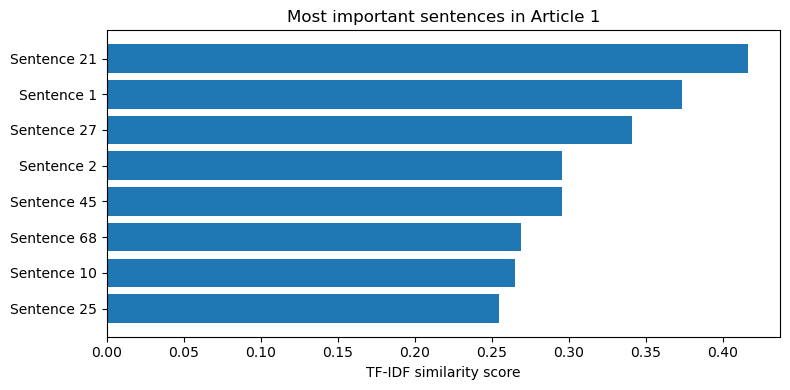

In [7]:
# Question 3.3
# Select the eight highest-scoring sentences
top_ids = np.argsort(sentence_scores)[-8:][::-1]

# Display the sentence importance scores
plt.figure(figsize=(8, 4))

plt.barh(
    [f"Sentence {i + 1}" for i in top_ids[::-1]],
    sentence_scores[top_ids][::-1]
)

plt.xlabel("TF-IDF similarity score")
plt.title("Most important sentences in Article 1")
plt.tight_layout()
plt.show()


In [8]:
# Question 3.4 
# Combine the sentences from Articles 2 to 5
all_sentences = []
article_sources = []

for i in range(1, 5):

    sentences = get_sentences(df.loc[i, "Content"])

    all_sentences.extend(sentences)

    article_sources.extend(
        [df.loc[i, "Article"]] * len(sentences)
    )

# Convert sentences into numerical features
lsa_tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2)
)

lsa_matrix = lsa_tfidf.fit_transform(all_sentences)

# Apply Latent Semantic Analysis
lsa = TruncatedSVD(
    n_components=3,
    random_state=42
)

lsa_sentence_vectors = lsa.fit_transform(lsa_matrix)

# Calculate sentence importance
lsa_scores = np.linalg.norm(
    lsa_sentence_vectors,
    axis=1
)

# Select two important sentences from each article
selected = []

for article in [
    "Article 2", "Article 3",
    "Article 4", "Article 5"
]:

    ids = np.where(
        np.array(article_sources) == article
    )[0]

    selected.extend(
        sorted(ids[np.argsort(lsa_scores[ids])[-2:]])
    )

# Display aggregate summary
print("AGGREGATE SUMMARY OF ARTICLES 2 TO 5:\n")

for i in selected:
    print(
        article_sources[i] + ":",
        all_sentences[i],
        "\n"
    )


AGGREGATE SUMMARY OF ARTICLES 2 TO 5:

Article 2: 309) One goal of reflexivity in qualitative research is to monitor such effects and thus enhance the accuracy of the research and ‘the credibility of the findings by accounting for researcher values, beliefs, knowledge, and biases’ (Cutcliffe, 2003: 137), that is, to gain plausibility by securing research’s trustworthiness (Buckner, 2005; Macbeth, 2001). 

Article 2: Reflexivity is crucial throughout all phases of the research process, including the formulation of a research question, collection and analysis of data, and drawing conclusions (Bradbury-Jones, 2007; Guillemin and Gillam, 2004). 

Article 3: In its simplest form, developmental research can be either  the study of the process and impact of specific instructional design and development efforts; or  a situation in which someone is performing instructional design, development, or evaluation activities and studying the process at the same time; or  the study of the instructio

In [9]:
#Question 3.4
# Divide cleaned articles into shorter text sections
chunks = []
chunk_sources = []

for i in range(1, 5):

    words = df.loc[i, "Clean_Text"].split()

    for start in range(0, len(words), 120):

        piece = " ".join(words[start:start + 120])

        if len(piece.split()) >= 40:
            chunks.append(piece)
            chunk_sources.append(df.loc[i, "Article"])

# Convert text sections into TF-IDF features
topic_tfidf = TfidfVectorizer(
    max_features=2500,
    min_df=2,
    max_df=0.9,
    ngram_range=(1, 2)
)

topic_matrix = topic_tfidf.fit_transform(chunks)

# Apply NMF topic modelling
nmf = NMF(
    n_components=3,
    init="nndsvda",
    random_state=42,
    max_iter=600
)

chunk_topics = nmf.fit_transform(topic_matrix)

# Get the topic keywords
terms = topic_tfidf.get_feature_names_out()

# Display the most important words in each topic
for t, weights in enumerate(nmf.components_, start=1):

    top = np.argsort(weights)[-10:][::-1]

    print(
        f"Topic {t}:",
        ", ".join(terms[top])
    )


Topic 1: research, development, developmental, developmental research, instructional, design, process, evaluation, design development, type
Topic 2: alpha, cronbach, cronbach alpha, instrument, science, reliability, values, science education, items, scales
Topic 3: triangulation, data, denzin, researcher, qualitative, fusch, multiple, data triangulation, methods, research


,Topic 1,Topic 2,Topic 3
Article 2,0.258,0.058,0.684
Article 3,0.980,0.008,0.012
Article 4,0.040,0.939,0.021
Article 5,0.036,0.010,0.955


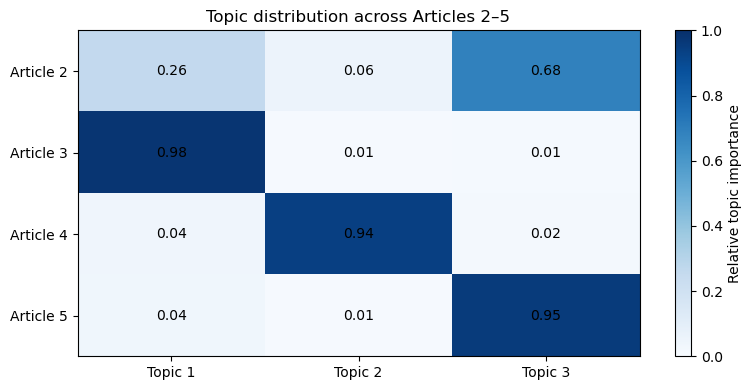

In [10]:
# Question 3.4 
# Calculate topic importance for each article
source_array = np.array(chunk_sources)

topic_rows = []

for article in [
    "Article 2", "Article 3",
    "Article 4", "Article 5"
]:

    mean_weight = chunk_topics[
        source_array == article
    ].mean(axis=0)

    topic_rows.append(
        mean_weight / mean_weight.sum()
    )

# Create topic distribution DataFrame
topic_df = pd.DataFrame(
    topic_rows,
    index=[
        "Article 2", "Article 3",
        "Article 4", "Article 5"
    ],
    columns=["Topic 1", "Topic 2", "Topic 3"]
)

display(topic_df.round(3))

# Plot the heatmap
plt.figure(figsize=(8, 4))

plt.imshow(
    topic_df,
    aspect="auto",
    cmap="Blues",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Relative topic importance")

plt.xticks(range(3), topic_df.columns)
plt.yticks(range(4), topic_df.index)

# Display values inside the heatmap
for i in range(4):
    for j in range(3):

        plt.text(
            j, i,
            f"{topic_df.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            color="black"
        )

plt.title("Topic distribution across Articles 2–5")
plt.tight_layout()
plt.show()


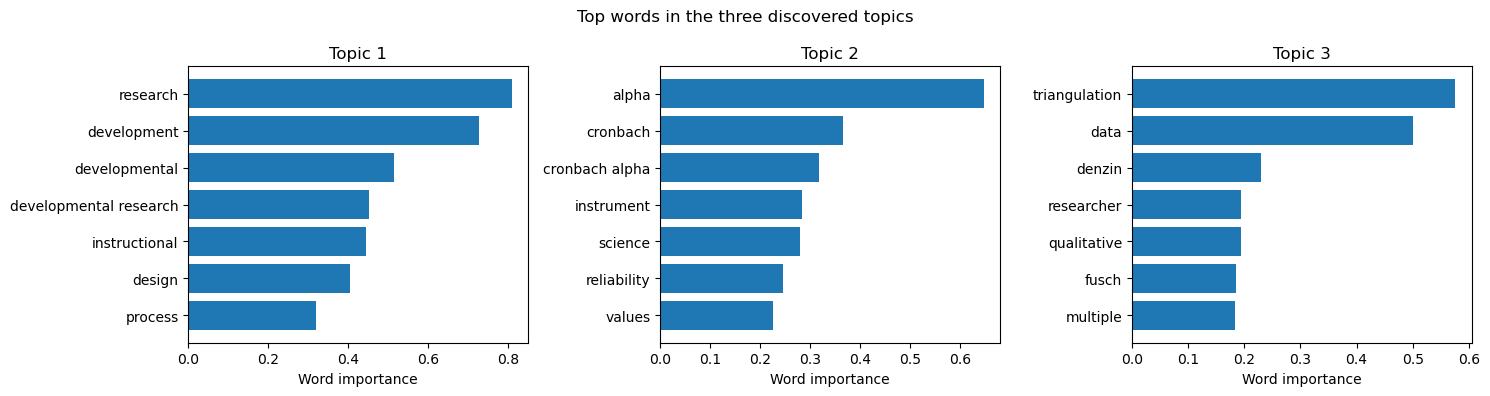

In [11]:
# Question 3.4
# Plot the main words belonging to each topic
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for topic_id, ax in enumerate(axes):

    weights = nmf.components_[topic_id]

    best = np.argsort(weights)[-7:]

    ax.barh(
        terms[best],
        weights[best]
    )

    ax.set_title(f"Topic {topic_id + 1}")
    ax.set_xlabel("Word importance")

plt.suptitle("Top words in the three discovered topics")
plt.tight_layout()
plt.show()
